## Import libraries

In [1]:
# Auto-reload modules when they change
%load_ext autoreload
%autoreload 2

print("✓ Auto-reload enabled - modules will update on each cell run")

✓ Auto-reload enabled - modules will update on each cell run


In [13]:
import sys
from pathlib import Path
from matplotlib import pyplot as plt

# Add project root to path
project_root = Path.cwd().parent.parent
sys.path.insert(0, str(project_root))

print(f"✓ Project root added: {project_root}")

from training.scripts.data_loader import create_dataloaders

✓ Project root added: /home/chris/Documents/waskiriSat/waskirisat-pl-aidev


## Load the Dataset

In [3]:
train_ds, val_ds, test_ds, classes = create_dataloaders(
    dataset_path="/home/chris/Downloads/output_img",
    batch_size=32
)

INFO:training.scripts.data_loader:Discovered 2 classes: ['0', '1']
INFO:training.scripts.data_loader:Split 'train': 1000 images
INFO:training.scripts.data_loader:Dataset loaded from: /home/chris/Downloads/output_img
INFO:training.scripts.data_loader:Split: train
INFO:training.scripts.data_loader:Total samples: 1000
INFO:training.scripts.data_loader:Classes: ['0', '1']
INFO:training.scripts.data_loader:  0: 389 (38.9%)
INFO:training.scripts.data_loader:  1: 611 (61.1%)
INFO:training.scripts.data_loader:Discovered 2 classes: ['0', '1']
INFO:training.scripts.data_loader:Split 'train': 1000 images
INFO:training.scripts.data_loader:Dataset loaded from: /home/chris/Downloads/output_img
INFO:training.scripts.data_loader:Split: train
INFO:training.scripts.data_loader:Total samples: 1000
INFO:training.scripts.data_loader:Classes: ['0', '1']
INFO:training.scripts.data_loader:  0: 389 (38.9%)
INFO:training.scripts.data_loader:  1: 611 (61.1%)
INFO:training.scripts.data_loader:Discovered 2 classes

## Visualize Image Batch

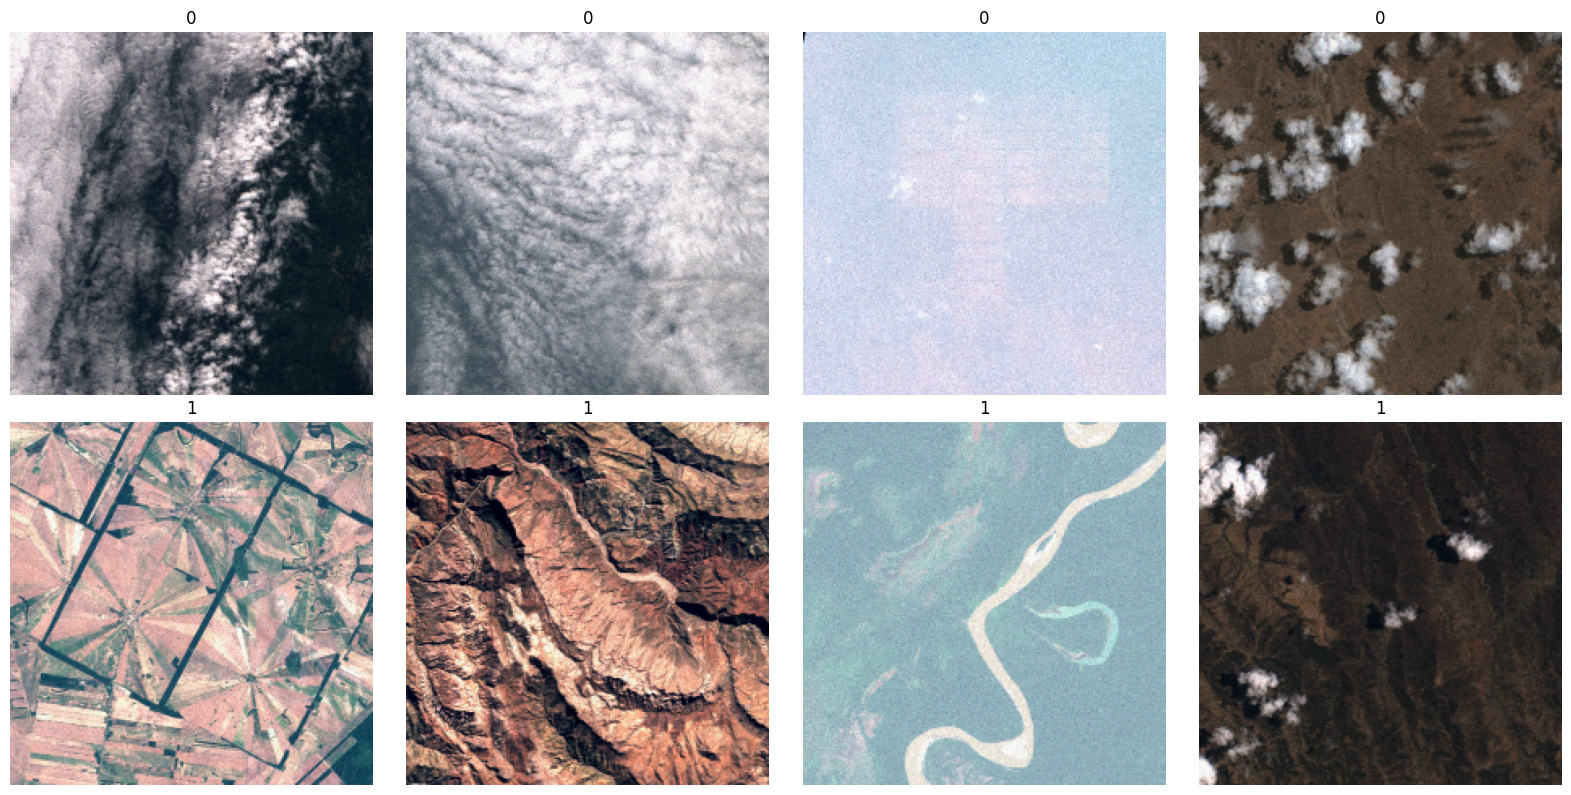

✓ Batch shape: (32, 224, 224, 3)
✓ Classes: ['0', '1']
✓ Samples displayed: 4 per class


In [4]:
from training.utils import display_batch_samples

# Display sample images from training dataset
display_batch_samples(
    dataset=train_ds,
    classes=classes,
    num_samples_per_class=4
)

In [5]:
## Inspect Dataset Statistics

In [6]:
# Inspect dataset information
print("📊 Dataset Statistics")
print("=" * 50)
print(f"Number of classes: {len(classes)}")
print(f"Class mapping: {classes}\n")

# Get batch info
for images, labels in train_ds.take(1):
    print(f"Training batch shape: {images.shape}")
    print(f"Labels shape: {labels.shape}")
    print(f"Image dtype: {images.dtype}")
    print(f"Image value range: [{images.numpy().min():.3f}, {images.numpy().max():.3f}]")
    break

# Count samples in each split (approximate)
train_count = len(list(train_ds.unbatch()))
val_count = len(list(val_ds.unbatch()))
test_count = len(list(test_ds.unbatch()))

print(f"\nDataset split sizes (approximate):")
print(f"  Train: {train_count} samples")
print(f"  Val:   {val_count} samples")
print(f"  Test:  {test_count} samples")
print(f"  Total: {train_count + val_count + test_count} samples")

📊 Dataset Statistics
Number of classes: 2
Class mapping: {0: '0', 1: '1'}

Training batch shape: (32, 224, 224, 3)
Labels shape: (32,)
Image dtype: <dtype: 'float32'>
Image value range: [0.000, 1.000]


2025-11-14 16:54:31.435269: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence
2025-11-14 16:54:31.999546: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence
2025-11-14 16:54:31.999546: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence



Dataset split sizes (approximate):
  Train: 1000 samples
  Val:   215 samples
  Test:  212 samples
  Total: 1427 samples


## Build Model Architecture

In [18]:
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import MobileNetV2
import os

# Get image shape from a batch
for images, _ in train_ds.take(1):
    input_shape = images.shape[1:]
    break

num_classes = len(classes)

print("📋 Building MobileNetV2 Transfer Learning Model")
print("=" * 50)

# Load pre-trained MobileNetV2 (ImageNet weights)
try:
    base_model = MobileNetV2(
        input_shape=input_shape,
        include_top=False,
        weights='imagenet'
    )
    print(f"✓ Loaded MobileNetV2 with ImageNet weights")
except Exception as e:
    print(f"⚠️  Could not load ImageNet weights: {str(e)}")
    print("   Loading MobileNetV2 without pre-trained weights...")
    base_model = MobileNetV2(
        input_shape=input_shape,
        include_top=False,
        weights=None
    )

# Freeze base model weights
base_model.trainable = False
print(f"✓ Base model frozen (trainable=False)")

# Build model with proven architecture
model = keras.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(64, activation='relu'),
    layers.Dense(num_classes, activation='softmax')
])

# Compile model
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("\n📋 Model Architecture")
print("=" * 50)
model.summary()

📋 Building MobileNetV2 Transfer Learning Model
⚠️  Could not load ImageNet weights: Unable to synchronously open file (file signature not found)
   Loading MobileNetV2 without pre-trained weights...
⚠️  Could not load ImageNet weights: Unable to synchronously open file (file signature not found)
   Loading MobileNetV2 without pre-trained weights...
✓ Base model frozen (trainable=False)

📋 Model Architecture
✓ Base model frozen (trainable=False)

📋 Model Architecture


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │        81,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 2)              │           130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,340,098 (8.93 MB)

 Trainable params: 82,114 (320.76 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## Train Model

In [19]:
# Define callbacks
early_stop = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True,
    verbose=1
)

# Train model
print("🚀 Training Model")
print("=" * 50)
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,
    callbacks=[early_stop],
    verbose=1
)

🚀 Training Model
Epoch 1/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 30s 822ms/step - accuracy: 0.6070 - loss: 0.6862 - val_accuracy: 0.6093 - val_loss: 0.6787
Epoch 2/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 25s 790ms/step - accuracy: 0.6110 - loss: 0.6743 - val_accuracy: 0.6093 - val_loss: 0.6712
Epoch 3/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 25s 789ms/step - accuracy: 0.6110 - loss: 0.6700 - val_accuracy: 0.6093 - val_loss: 0.6693
Epoch 4/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 23s 717ms/step - accuracy: 0.6110 - loss: 0.6696 - val_accuracy: 0.6093 - val_loss: 0.6691
Epoch 5/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 28s 866ms/step - accuracy: 0.6110 - loss: 0.6684 - val_accuracy: 0.6093 - val_loss: 0.6691
Epoch 6/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 24s 760ms/step - accuracy: 0.6110 - loss: 0.6683 - val_accuracy: 0.6093 - val_loss: 0.6691
Epoch 7/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 25s 783ms/step - accuracy: 0.6110 - loss: 0.6684 - val_accuracy: 0.6093 - val_loss: 0.6691
Epoch 8/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 23s 728ms/step - accuracy: 0.6110 - loss: 

## Evaluate Model Performance

📈 Model Evaluation
Test Loss: 0.6673
Test Accuracy: 0.6132
Test Loss: 0.6673
Test Accuracy: 0.6132


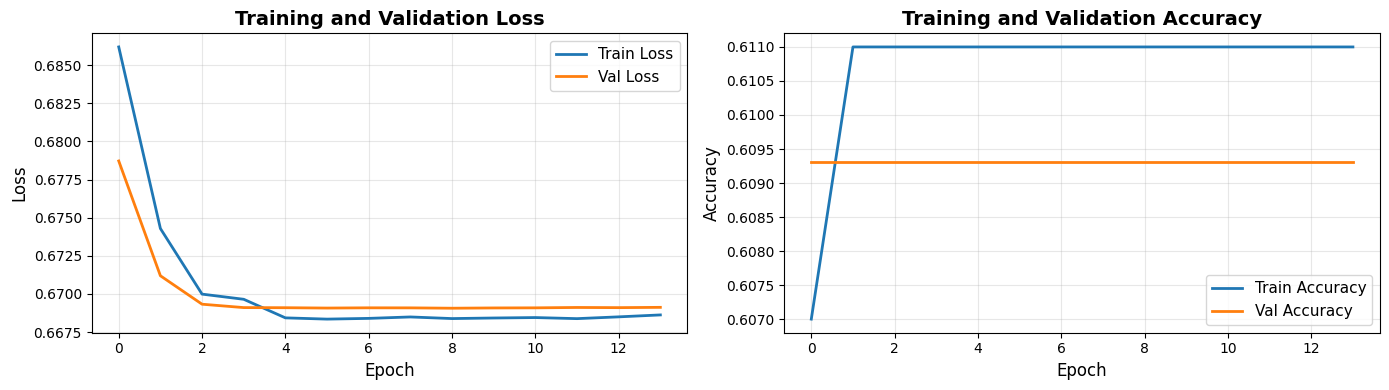

In [20]:
# Evaluate on test set
print("📈 Model Evaluation")
print("=" * 50)
test_loss, test_accuracy = model.evaluate(test_ds, verbose=0)
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

# Plot training history
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Loss plot
axes[0].plot(history.history['loss'], label='Train Loss', linewidth=2)
axes[0].plot(history.history['val_loss'], label='Val Loss', linewidth=2)
axes[0].set_xlabel('Epoch', fontsize=12)
axes[0].set_ylabel('Loss', fontsize=12)
axes[0].set_title('Training and Validation Loss', fontsize=14, fontweight='bold')
axes[0].legend(fontsize=11)
axes[0].grid(alpha=0.3)

# Accuracy plot
axes[1].plot(history.history['accuracy'], label='Train Accuracy', linewidth=2)
axes[1].plot(history.history['val_accuracy'], label='Val Accuracy', linewidth=2)
axes[1].set_xlabel('Epoch', fontsize=12)
axes[1].set_ylabel('Accuracy', fontsize=12)
axes[1].set_title('Training and Validation Accuracy', fontsize=14, fontweight='bold')
axes[1].legend(fontsize=11)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Save and Quantize Model

In [ ]:
import os
from pathlib import Path
import tensorflow as tf
import json

# Create models directory if it doesn't exist
models_dir = Path("/home/chris/Documents/waskiriSat/waskirisat-pl-aidev/training/models")
models_dir.mkdir(parents=True, exist_ok=True)

print("Saving and Quantizing Model")
print("=" * 50)

# Save original model
model_path = models_dir / "mobilenetv2_classifier.keras"
model.save(str(model_path))
original_size = os.path.getsize(model_path) / (1024 * 1024)  # Convert to MB
print(f"✓ Original model saved: {model_path}")
print(f"  Size: {original_size:.2f} MB")

# Convert to TensorFlow Lite with full integer quantization (uint8)
print("\nConverting to TensorFlow Lite with Full Integer Quantization (uint8)...")

# Create a function to generate representative data
def representative_dataset():
    """Generate representative data from training dataset for quantization"""
    for images, _ in train_ds.take(100):  # Use 100 batches for calibration
        # Ensure images are float32 and normalized to [0, 1]
        yield [tf.cast(images, tf.float32)]

# Create converter with full integer quantization
converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.representative_dataset = representative_dataset
converter.target_spec.supported_ops = [
    tf.lite.OpsSet.TFLITE_BUILTINS_INT8
]
converter.inference_input_type = tf.uint8
converter.inference_output_type = tf.uint8

tflite_model_uint8 = converter.convert()

# Save uint8 quantized model
quantized_model_path = models_dir / "mobilenetv2_classifier_quantized.tflite"
with open(quantized_model_path, 'wb') as f:
    f.write(tflite_model_uint8)

quantized_size = os.path.getsize(quantized_model_path) / (1024 * 1024)
print(f"✓ Quantized model saved: {quantized_model_path}")
print(f"  Quantization: uint8 (full integer)")
print(f"  Size: {quantized_size:.2f} MB")

# Calculate compression ratio
compression_ratio = (1 - quantized_size / original_size) * 100
print(f"\nModel Compression Summary:")
print(f"  Original size: {original_size:.2f} MB")
print(f"  Quantized size: {quantized_size:.2f} MB")
print(f"  Compression: {compression_ratio:.1f}%")
print(f"  Size reduction: {original_size - quantized_size:.2f} MB")

# Save class mapping
classes_path = models_dir / "classes.json"
with open(classes_path, 'w') as f:
    json.dump(classes, f, indent=2)
print(f"\n✓ Class mapping saved: {classes_path}")

print("\nModel training and quantization complete!")
print(f"All models saved in: {models_dir}")

💾 Saving and Quantizing Model
✓ Original model saved: /home/chris/Documents/waskiriSat/waskirisat-pl-aidev/training/models/mobilenetv2_classifier.keras
  Size: 10.11 MB

🔄 Converting to TensorFlow Lite with Full Integer Quantization (uint8)...
✓ Original model saved: /home/chris/Documents/waskiriSat/waskirisat-pl-aidev/training/models/mobilenetv2_classifier.keras
  Size: 10.11 MB

🔄 Converting to TensorFlow Lite with Full Integer Quantization (uint8)...
INFO:tensorflow:Assets written to: /tmp/tmpqij4paa8/assets
INFO:tensorflow:Assets written to: /tmp/tmpqij4paa8/assets


INFO:tensorflow:Assets written to: /tmp/tmpqij4paa8/assets


Saved artifact at '/tmp/tmpqij4paa8'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='keras_tensor_1088')
Output Type:
  TensorSpec(shape=(None, 2), dtype=tf.float32, name=None)
Captures:
  123131607469904: TensorSpec(shape=(), dtype=tf.resource, name=None)
  123131607471440: TensorSpec(shape=(), dtype=tf.resource, name=None)
  123131607471248: TensorSpec(shape=(), dtype=tf.resource, name=None)
  123131607470480: TensorSpec(shape=(), dtype=tf.resource, name=None)
  123131607472016: TensorSpec(shape=(), dtype=tf.resource, name=None)
  123131607467984: TensorSpec(shape=(), dtype=tf.resource, name=None)
  123131607471632: TensorSpec(shape=(), dtype=tf.resource, name=None)
  123131607471824: TensorSpec(shape=(), dtype=tf.resource, name=None)
  123131607471056: TensorSpec(shape=(), dtype=tf.resource, name=None)
  123131607472976: TensorSpec(shape=(), dtype=tf.resource, name=None)
  123131607

/home/chris/Documents/waskiriSat/waskirisat-pl-aidev/venv/lib/python3.12/site-packages/tensorflow/lite/python/convert.py:863: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
W0000 00:00:1763156066.939818    6662 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1763156066.939834    6662 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
2025-11-14 17:34:26.939985: I tensorflow/cc/saved_model/reader.cc:83] Reading SavedModel from: /tmp/tmpqij4paa8
2025-11-14 17:34:26.951219: I tensorflow/cc/saved_model/reader.cc:52] Reading meta graph with tags { serve }
2025-11-14 17:34:26.951235: I tensorflow/cc/saved_model/reader.cc:147] Reading SavedModel debug info (if present) from: /tmp/tmpqij4paa8
2025-11-14 17:34:27.084426: I tensorflow/cc/saved_model/loader.cc:236] Restoring SavedModel bundle.
2025-11-14 17:34:27.811597: I tensorflow/cc/saved_model/loader.cc:220] Running initialization op on S

✓ Quantized model saved: /home/chris/Documents/waskiriSat/waskirisat-pl-aidev/training/models/mobilenetv2_classifier_quantized.tflite
  Quantization: uint8 (full integer)
  Size: 2.61 MB

📊 Model Compression Summary:
  Original size: 10.11 MB
  Quantized size: 2.61 MB
  Compression: 74.2%
  Size reduction: 7.51 MB

✓ Class mapping saved: /home/chris/Documents/waskiriSat/waskirisat-pl-aidev/training/models/classes.json

✅ Model training and quantization complete!
📁 All models saved in: /home/chris/Documents/waskiriSat/waskirisat-pl-aidev/training/models


fully_quantize: 0, inference_type: 6, input_inference_type: UINT8, output_inference_type: UINT8
2025-11-14 17:35:56.254380: W tensorflow/compiler/mlir/lite/flatbuffer_export.cc:3705] Skipping runtime version metadata in the model. This will be generated by the exporter.
